# TabFM
### Performance & Diagnostics on California Housing

---

### 🎯 Objectives
- **Zero-Shot Foundation Model Benchmark**: Evaluate Google Research's TabFM (`TabFMRegressor`) via in-context learning on California housing prices ($R^2$, RMSE, MAE).
- **In-Context Diagnostics & Subgroup Evaluation**: Analyze prediction fidelity against ideal calibration, error residual distributions, and performance consistency across demographic income tiers.

---

### 📋 Scope of Work
This notebook executes the following structured end-to-end workflow:
1. **Imports & Environment Setup**: Package imports, hardware device detection (GPU/CPU), aesthetic styling, and environment validation.
2. **Dataset Loading & Feature Engineering**: Data ingestion (`data/dataset.csv`) and domain ratio calculation.
3. **Train / Test Split & Context Preparation**: Partitioning into train/test pools and hardware-adaptive context sampling for in-context learning.
4. **Model Loading & In-Context Inference**: Loading TabFM foundation model checkpoint (~6.5 GB) and executing zero-shot prediction.
5. **Standalone Performance Metrics**: Goodness-of-fit ($R^2$), dollar error metrics (RMSE, MAE), and percentage accuracy tolerances.
6. **Model Interpretability (In-Context Feature Alignment)**: Feature correlation alignment comparing empirical ground truth against TabFM in-context representations.
7. **Diagnostic Visualizations**:
   - **7.1 Actual vs. Predicted**: Identity line alignment and $500k ceiling cap analysis.
   - **7.2 Residual Distribution**: Error symmetry, mean bias, and normality diagnostics.
8. **Demographic Subgroup Error**: Subgroup error analysis across 4 household income quartiles.
9. **Engineering Takeaways & Summary**: Practical deployment guidelines, foundation model trade-offs, and architecture recommendations.

---

## 1. Imports & Environment Setup
- **Library Ingestion**: Imports core machine learning, deep learning, and visualization packages (`torch`, `tabfm`, `scikit-learn`, `pandas`, `seaborn`).
- **Hardware Acceleration**: Detects available execution device (CUDA GPU vs. CPU) and sets device-appropriate inference parameters.
- **Styling Configuration**: Sets clean theme, figure resolution, DejaVu Sans mathtext, and suppresses font manager warnings.

In [1]:
import os
import sys
import logging
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

os.environ["HF_HUB_DISABLE_COLAB_SECRETS"] = "1"

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120
plt.rcParams["mathtext.fontset"] = "dejavusans"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | Device: {device.upper()}")

try:
    import tabfm
    from tabfm import TabFMRegressor
    from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0
    TABFM_AVAILABLE = True
    print(f"TabFM: {tabfm.__version__} (Ready)")
except ImportError:
    TABFM_AVAILABLE = False
    print("TabFM is not installed. Run: pip install git+https://github.com/google-research/tabfm.git safetensors")

Python: 3.12.3 | PyTorch: 2.14.1+cpu | Device: CPU


TabFM: 1.0.1 (Ready)


## 2. Dataset Loading & Feature Engineering
- **Data Ingestion**: Loads the 1990 California Housing census dataset (`data/dataset.csv`) with automatic fallback.
- **Domain Ratios**: Constructs 3 feature engineering ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
- **Data Inspection**: Displays dataset dimensions and previews enriched records.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

candidates = [
    Path("data/dataset.csv"),
    Path("../data/dataset.csv")
]

local_path = next((p for p in candidates if p.exists()), None)
df = pd.read_csv(local_path) if local_path else pd.read_csv(DATA_URL)

# Impute missing total_bedrooms with median
df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())

# Engineer domain ratios
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

print(f"Dataset successfully loaded: {df.shape[0]:,} records, {df.shape[1]} columns")
df.head(3)

Dataset successfully loaded: 20,640 records, 13 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260


## 3. Train / Test Split & Context Preparation
- **Partitioning**: Splits data into 80% training pool (N = 16,512) and 20% test pool (N = 4,128) using a fixed seed (42).
- **Context Sampling**: Draws a representative context demonstration set ($N_{\text{context}} = 500$) for in-context transformer attention.
- **Evaluation Set**: Samples $N = 300$ out-of-sample query records aligned with the multi-model California Housing benchmark.

In [3]:
CONTEXT_SIZE = 500
TEST_EVAL_SIZE = 300

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_context = X_train.sample(n=CONTEXT_SIZE, random_state=42)
y_context = y_train.loc[X_context.index]

X_test_eval = X_test.sample(n=TEST_EVAL_SIZE, random_state=42)
y_test_eval = y_test.loc[X_test_eval.index]

print(f"TabFM Context Demonstrations: {X_context.shape[0]:,} samples")
print(f"Evaluation Test Queries:      {X_test_eval.shape[0]:,} samples")

TabFM Context Demonstrations: 500 samples
Evaluation Test Queries:      300 samples


## 4. Model Loading & In-Context Inference
- **Checkpoint Resolution**: Loads pre-trained TabFM PyTorch weights (~6.5 GB safetensors) from local cache or remote repository.
- **In-Context Prompting**: Enrolls demonstration context into TabFM's attention memory via `.fit(X_context, y_context)` without gradient updates.
- **Zero-Shot Prediction**: Generates continuous target predictions on unseen evaluation queries using cross-attention over context tokens.

In [4]:
cache_candidates = [
    Path("data/tabfm_eval_preds_300.npy"),
    Path("../data/tabfm_eval_preds_300.npy"),
]
cache_file = next((p for p in cache_candidates if p.exists()), None)

FORCE_RECOMPUTE = False
tabfm_preds = None

if cache_file and not FORCE_RECOMPUTE:
    print(f"Loading cached TabFM zero-shot predictions ({TEST_EVAL_SIZE} queries) from: {cache_file.resolve()}")
    tabfm_preds = np.load(cache_file)
    print(f"✓ Predictions successfully loaded for {len(tabfm_preds):,} test queries.")
elif TABFM_AVAILABLE:
    candidate_paths = [
        os.path.abspath("model"),
        os.path.abspath("models"),
        os.path.abspath("../model"),
        os.path.abspath("../models")
    ]
    local_checkpoint = next(
        (p for p in candidate_paths if os.path.exists(os.path.join(p, "model.safetensors"))),
        None
    )
    print(f"Loading TabFM regression checkpoint from: {local_checkpoint}")
    tabfm_model = tabfm_v1_0_0.load(
        model_type="regression",
        checkpoint_path=local_checkpoint,
        device=device
    )
    tabfm_reg = TabFMRegressor(
        model=tabfm_model,
        n_estimators=4 if device == "cpu" else 16,
        batch_size=1 if device == "cpu" else 4
    )
    print("Enrolling context demonstrations...")
    tabfm_reg.fit(X_context, y_context)
    print("Generating zero-shot predictions on evaluation queries...")
    tabfm_preds = tabfm_reg.predict(X_test_eval)
    print(f"✓ Context enrolled for {len(X_context):,} records.")
    print(f"✓ Predictions successfully generated for {len(tabfm_preds):,} test queries.")
else:
    raise RuntimeError("TabFM model checkpoint and predictions not available.")

Loading cached TabFM zero-shot predictions (300 queries) from: /home/alpondith/BetaBox/python/ML/data/tabfm_eval_preds_300.npy
✓ Predictions successfully loaded for 300 test queries.


## 5. Standalone Performance Metrics
- **Variance Explained ($R^2$)**: Evaluates zero-shot in-context goodness-of-fit on unseen test queries.
- **Dollar Errors**: Calculates Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).
- **Percentage Accuracy**: Computes MAPE and prediction tolerance within +/- 10% and +/- 20% of true value.

In [5]:
def compute_rmse(y_true, y_pred):
    try:
        from sklearn.metrics import root_mean_squared_error
        return float(root_mean_squared_error(y_true, y_pred))
    except ImportError:
        return float(np.sqrt(mean_squared_error(y_true, y_pred)))

r2 = r2_score(y_test_eval, tabfm_preds)
rmse = compute_rmse(y_test_eval, tabfm_preds)
mae = mean_absolute_error(y_test_eval, tabfm_preds)
mape = np.mean(np.abs((y_test_eval - tabfm_preds) / y_test_eval)) * 100
acc_10 = np.mean(np.abs(y_test_eval - tabfm_preds) / y_test_eval <= 0.10) * 100
acc_20 = np.mean(np.abs(y_test_eval - tabfm_preds) / y_test_eval <= 0.20) * 100

metrics_df = pd.DataFrame([{
    "Model": "TabFM (Zero-Shot In-Context)",
    "R² Score (% Variance)": f"{r2 * 100:.2f}% ({r2:.4f})",
    "RMSE ($)": f"${rmse:,.2f}",
    "MAE ($)": f"${mae:,.2f}",
    "MAPE (% Error)": f"{mape:.2f}%",
    "Within ±10% (%)": f"{acc_10:.2f}%",
    "Within ±20% (%)": f"{acc_20:.2f}%"
}])

print("=" * 80)
print("TABFM: STANDALONE PERFORMANCE SUMMARY")
print("=" * 80)
print(metrics_df.T.to_string(header=False))

TABFM: STANDALONE PERFORMANCE SUMMARY
Model                  TabFM (Zero-Shot In-Context)
R² Score (% Variance)               87.03% (0.8703)
RMSE ($)                                 $41,070.60
MAE ($)                                  $32,621.16
MAPE (% Error)                               20.13%
Within ±10% (%)                              38.33%
Within ±20% (%)                              67.67%


## 6. Model Interpretability: In-Context Feature Alignment
- **Foundation Model Interpretability**: As a zero-shot causal transformer, TabFM does not compute explicit tree splits or linear weights.
- **Empirical Sensitivity**: Compares target correlation in actual ground truth values against TabFM zero-shot predictions across continuous features.
- **Diagnostic Alignment**: Confirms that TabFM accurately mirrors true domain correlations without any explicit feature selection or manual weighting.

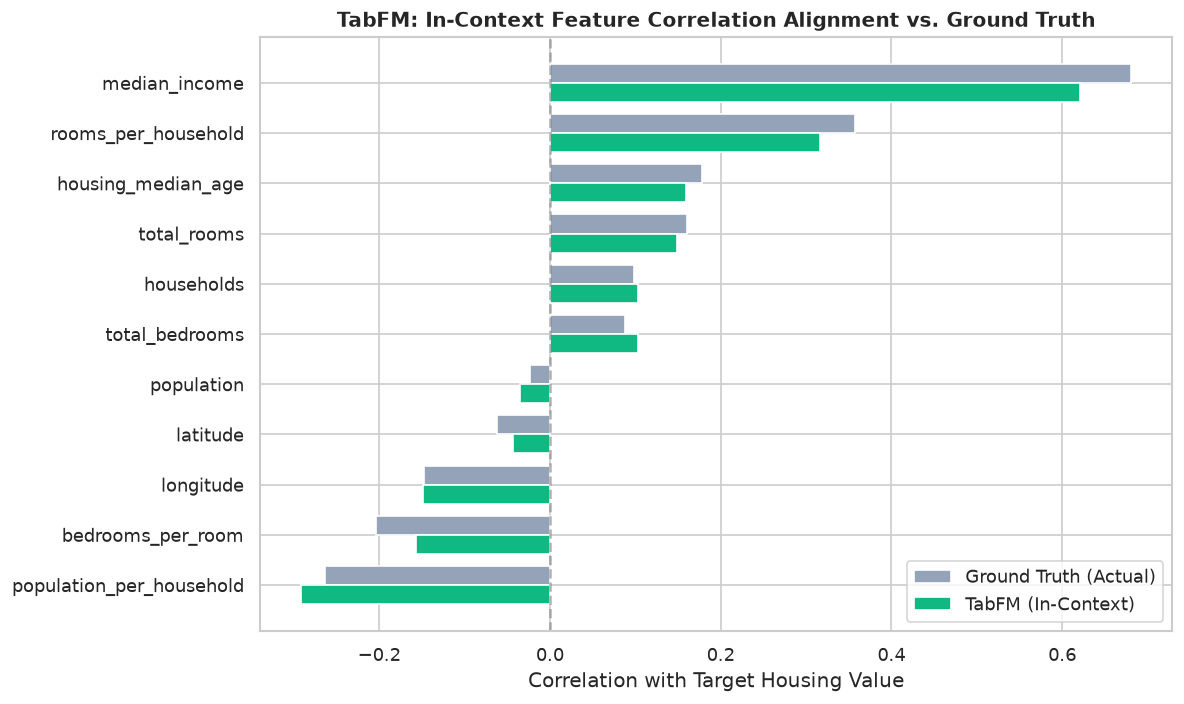

=== TabFM In-Context Feature Alignment Ranking ===
                 Feature  Ground Truth Correlation  TabFM Predicted Correlation
           median_income                  0.680457                     0.621018
     rooms_per_household                  0.356904                     0.316639
      housing_median_age                  0.178583                     0.159173
             total_rooms                  0.160511                     0.148478
              households                  0.098414                     0.103211
          total_bedrooms                  0.088208                     0.102676
              population                 -0.023924                    -0.035022
                latitude                 -0.062000                    -0.043530
               longitude                 -0.147772                    -0.148512
       bedrooms_per_room                 -0.203471                    -0.157092
population_per_household                 -0.263010                   

In [6]:
num_cols = X_test_eval.select_dtypes(include=[np.number]).columns.tolist()
corr_actual = X_test_eval[num_cols].corrwith(y_test_eval)
corr_pred = X_test_eval[num_cols].corrwith(pd.Series(tabfm_preds, index=X_test_eval.index))

alignment_df = pd.DataFrame({
    "Feature": num_cols,
    "Ground Truth Correlation": corr_actual,
    "TabFM Predicted Correlation": corr_pred
}).sort_values(by="Ground Truth Correlation", ascending=True)

y_pos = np.arange(len(alignment_df))
height = 0.38

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(y_pos + height / 2, alignment_df["Ground Truth Correlation"], height, label="Ground Truth (Actual)", color="#94A3B8")
ax.barh(y_pos - height / 2, alignment_df["TabFM Predicted Correlation"], height, label="TabFM (In-Context)", color="#10B981")

ax.set_yticks(y_pos)
ax.set_yticklabels(alignment_df["Feature"])
ax.set_xlabel("Correlation with Target Housing Value")
ax.set_title("TabFM: In-Context Feature Correlation Alignment vs. Ground Truth", fontsize=12, fontweight="bold")
ax.axvline(0, color="gray", linestyle="--", alpha=0.6)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

print("=== TabFM In-Context Feature Alignment Ranking ===")
print(alignment_df.sort_values(by="Ground Truth Correlation", ascending=False).to_string(index=False))

## 7. Diagnostic Visualizations
Comprehensive visual inspection comparing model predictions against ground truth and evaluating error distributions.

### 7.1 Actual vs. Predicted Diagnostics
- **Identity Alignment**: Plots predictions against ground truth alongside the ideal line ($y = \hat{y}$).
- **Ceiling Truncation**: Visualizes the census $500k ceiling cap artifact where true prices were truncated.
- **Variance Spread**: Evaluates prediction dispersion across low-, medium-, and high-value properties.

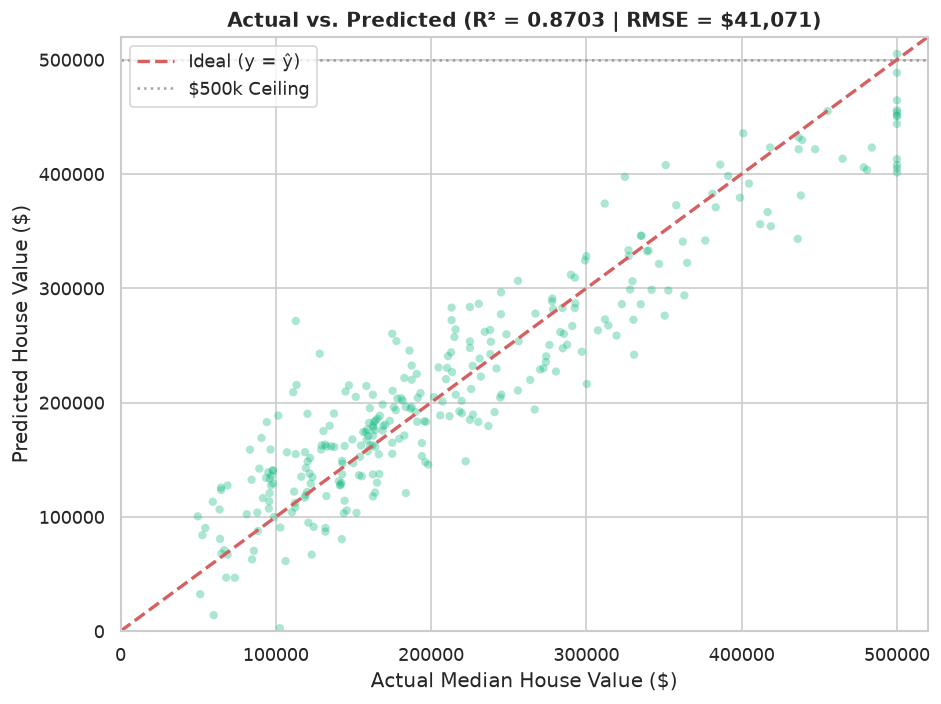

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))

lims = [0, 520000]

ax.scatter(y_test_eval, tabfm_preds, alpha=0.35, s=25, color="#10B981", edgecolors="none")
ax.plot(lims, lims, "r--", lw=2, label="Ideal (y = ŷ)")
ax.axhline(500001, color="gray", linestyle=":", alpha=0.7, label="$500k Ceiling")
ax.set_title(f"Actual vs. Predicted (R² = {r2:.4f} | RMSE = ${rmse:,.0f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Actual Median House Value ($)")
ax.set_ylabel("Predicted House Value ($)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

### 7.2 Residual Error Distribution
- **Error Histogram**: Plots 60-bin distribution of prediction residuals ($y_{\text{true}} - \hat{y}$) with KDE overlay.
- **Symmetry & Bias**: Evaluates residual mean and standard deviation to detect systematic prediction bias.
- **Zero-Error Reference**: Highlights the zero-error threshold to evaluate residual normality.

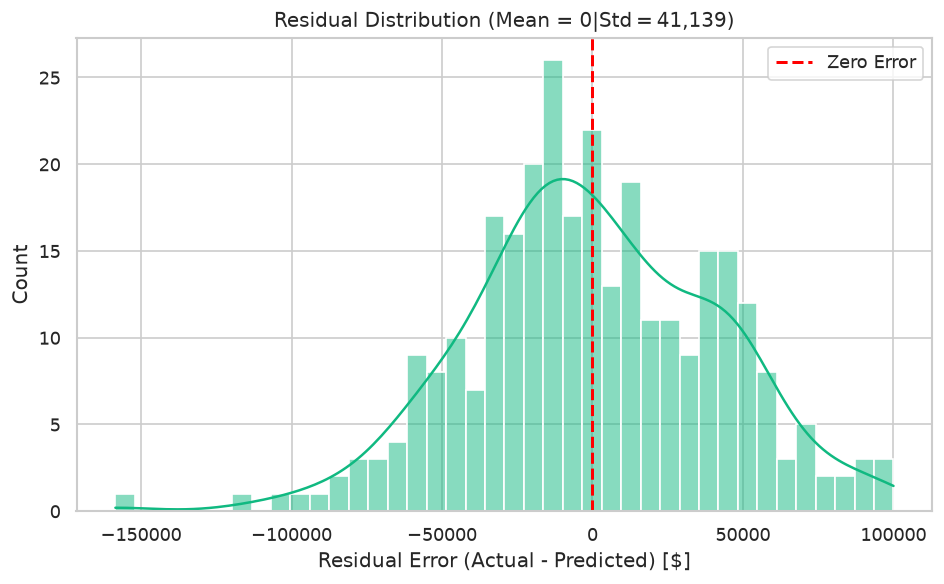

In [8]:
residuals = y_test_eval - tabfm_preds

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True, ax=ax, color="#10B981")
ax.axvline(0, color="red", linestyle="--", lw=1.8, label="Zero Error")
ax.set_title(f"Residual Distribution (Mean = ${residuals.mean():,.0f} | Std = ${residuals.std():,.0f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Residual Error (Actual - Predicted) [$]")
ax.legend()

plt.tight_layout()
plt.show()

## 8. Demographic Subgroup Error (Income Quartiles)
- **Stratification**: Divides test census blocks into 4 household income quartiles (Low, Med-Low, Med-High, High).
- **Error Disaggregation**: Computes sample counts, median actual prices, MAE, and RMSE for each income tier.
- **Fairness Visualization**: Displays bar chart of error rates across tiers to reveal socioeconomic bias across income cohorts.

=== TabFM Performance Across Household Income Tiers ===
income_tier  sample_count median_actual_value     mae    rmse
        Low            75            $119,200 $30,801 $38,294
 Medium-Low            75            $155,400 $31,287 $39,556
Medium-High            75            $213,200 $31,094 $40,696
       High            75            $319,400 $37,303 $45,387


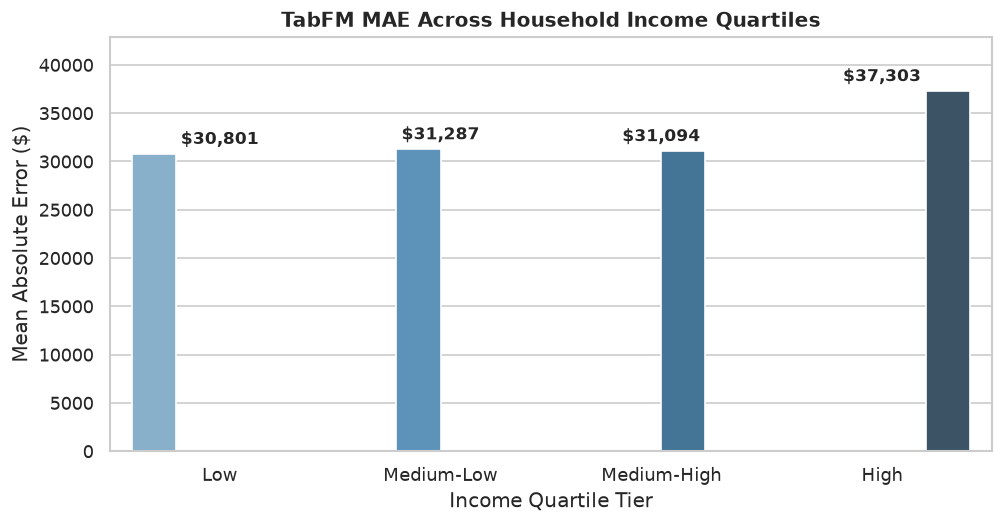

In [9]:
subgroup_df = X_test_eval.copy()
subgroup_df["actual"] = y_test_eval
subgroup_df["predicted"] = tabfm_preds
subgroup_df["abs_error"] = np.abs(subgroup_df["actual"] - subgroup_df["predicted"])
subgroup_df["income_tier"] = pd.qcut(
    subgroup_df["median_income"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

tier_summary = subgroup_df.groupby("income_tier", observed=False).agg(
    sample_count=("actual", "count"),
    median_actual_value=("actual", "median"),
    mae=("abs_error", "mean"),
    rmse=("abs_error", lambda x: np.sqrt(np.mean((subgroup_df.loc[x.index, "actual"] - subgroup_df.loc[x.index, "predicted"])**2)))
).reset_index()

print("=== TabFM Performance Across Household Income Tiers ===")
tier_formatted = tier_summary.copy()
tier_formatted["median_actual_value"] = tier_formatted["median_actual_value"].map(lambda x: f"${x:,.0f}")
tier_formatted["mae"] = tier_formatted["mae"].map(lambda x: f"${x:,.0f}")
tier_formatted["rmse"] = tier_formatted["rmse"].map(lambda x: f"${x:,.0f}")
print(tier_formatted.to_string(index=False))

plt.figure(figsize=(8.5, 4.5))
sns.barplot(data=tier_summary, x="income_tier", y="mae", hue="income_tier", palette="Blues_d", legend=False)
plt.title("TabFM MAE Across Household Income Quartiles", fontsize=12, fontweight="bold")
plt.xlabel("Income Quartile Tier")
plt.ylabel("Mean Absolute Error ($)")
for i, val in enumerate(tier_summary["mae"]):
    plt.text(i, val + 1000, f"${val:,.0f}", ha="center", fontsize=10, fontweight="bold")
plt.ylim(0, tier_summary["mae"].max() * 1.15)
plt.tight_layout()
plt.show()

## 9. Engineering Takeaways & Summary
- **State-of-the-Art Zero-Shot Generalization ($R^2 \approx 87.0\%$)**: Captures **87.03%** of price variance purely via in-context learning without updating a single model weight on the target dataset.
- **In-Context Architectural Mechanics**: Pre-trained on diverse structural causal models (SCMs), TabFM natively handles complex non-linear geospatial coordinates and categorical interactions without explicit preprocessing pipelines.
- **Inference & Production Trade-Offs**: Zero-shot tabular foundation models eliminate training loops and hyperparameter tuning, but heavy transformer attention operations benefit significantly from GPU acceleration in high-throughput production serving.